# Polar bathymetry seam test

Reproducer + regression test for the antimeridian seam in `Topo.set_depth_from_xesmf`
on polar-stereographic grids. See mom6_forge PR #146.

**Bug (before the fix):** the xESMF regridder was called with `periodic=False`, so
destination cells that fall in the ~1-cell gap between the global source's +180 and -180
endpoints received no enclosing source quad. On a lat/lon regional grid the antimeridian
never intersects the domain; on a polar grid it always does, producing a visible seam
along the antimeridian.

**Fix:** infer source periodicity from its lon span and pass `periodic=True` through when
the source is global.

**How to read this notebook:** run all cells with a mom6_forge that includes the fix and
the plot in the last cell should be smooth across the antimeridian. Check out `main` (before
the PR) and rerun to see the seam.

Run with the `mom6_forge` conda env.

In [6]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt


from mom6_forge.grid import Grid
from mom6_forge.topo import Topo

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Build the Arctic polar grid

EPSG:3995 Arctic polar stereographic, ±1000 km around the pole, 50 km resolution.
The outer rim of the grid spans the full ±180° lon range, so the antimeridian falls
*inside* the domain.

In [7]:
arctic_grid = Grid.from_projection(
    crs="EPSG:3995",
    x_min=-1_000_000,
    x_max= 1_000_000,
    y_min=-1_000_000,
    y_max= 1_000_000,
    resolution_m=50_000,
    name="arctic_50km",
)

print(f"Grid size: {arctic_grid.nx} x {arctic_grid.ny}")
print(f"Lat range: {arctic_grid.tlat.values.min():.1f}° to {arctic_grid.tlat.values.max():.1f}°")
print(f"Lon range: {arctic_grid.tlon.values.min():.1f}° to {arctic_grid.tlon.values.max():.1f}°")

Grid size: 40 x 40
Lat range: 77.4° to 89.7°
Lon range: -178.5° to 178.5°


## 2. Regrid GEBCO onto the polar grid

Use `set_depth_from_xesmf` directly (rather than the opinionated `set_from_dataset`) so
we exercise the exact code path the PR modified. `GEBCO_2024.nc` has `lon` = -180..180,
`lat`, and `elevation` (positive above MSL).

In [8]:
GEBCO = "/glade/campaign/cgd/oce/projects/CROCODILE/workshops/2026/CrocoDash/data/gebco_2026/GEBCO_2026_coarse_x8.nc"

topo = Topo(arctic_grid, min_depth=10.0, git=False)

topo.set_src(
    bathymetry_path=GEBCO,
    longitude_coordinate_name="lon",
    latitude_coordinate_name="lat",
    vertical_coordinate_name="elevation",
    is_input_positive_below_msl=False,
)

topo.set_depth_from_xesmf(regridding_method="bilinear")

Slicing source bathymetry to domain: (-177.13759477388825, 180.0) x (77.03740063459344, 90.0) with buffer 0.5
**NOTE**
            If bathymetry setup fails (e.g. kernel crashes), restart the kernel and edit this cell.
            Call ``[topo_object_name].mpi_set_depth_from_xesmf()`` instead. Follow the given instructions for using mpi
            and ESMF_Regrid outside of a python environment. This breaks up the process, so be sure to call
            ``[topo_object_name].fill_inland_lakes_and_channels()`` after regridding with mpi.
--- xESMF Regridding Info ---
  Source:        lat=404, lon=10800  (4,363,200 points)  [8.82 MB]
  Destination:   ny=40, nx=40  (1,600 points)  [0.05 MB]
  Method:        bilinear
  Weights:       generating new weights
  Periodic:      True
  Locstream out: False
-----------------------------
Generating regridding weights using xESMF with method 'bilinear'...


/glade/work/manishrv/conda-envs/dev_mf/lib/python3.13/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


## 3. Sanity-check that the fix actually fired

The fix auto-detects source periodicity. Recompute the same check the fix does and
assert it evaluated to `True` on this global GEBCO source.

In [10]:
src_lons = np.asarray(topo.src.ds[topo.src.lon_name].values)
src_dlon = float(src_lons[1] - src_lons[0])
src_span = float(src_lons.max() - src_lons.min()) + abs(src_dlon)
print(f"Source lon span (incl. dlon): {src_span:.4f}°  →  periodic={src_span >= 359.9}")
assert src_span >= 359.9, "GEBCO source should be detected as periodic"
print("OK: fix path exercised.")

Source lon span (incl. dlon): 360.0000°  →  periodic=True
OK: fix path exercised.


## 4. Visual regression: plot the bathymetry

Two views:

- **Left (index space):** the seam, if present, shows up as a vertical/horizontal line of
  anomalous cells at the domain edge that touches the antimeridian. Easy to see because
  the affected cells sit on a straight raster line.
- **Right (geographic space):** the seam, if present, is a radial spoke running from the
  pole outward along lon=±180°. With the fix, the spoke disappears.

/glade/derecho/scratch/manishrv/tmp/ipykernel_1070/2222753701.py:12: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im1 = axes[1].pcolormesh(tlon, tlat, depth, cmap="viridis", shading="auto")


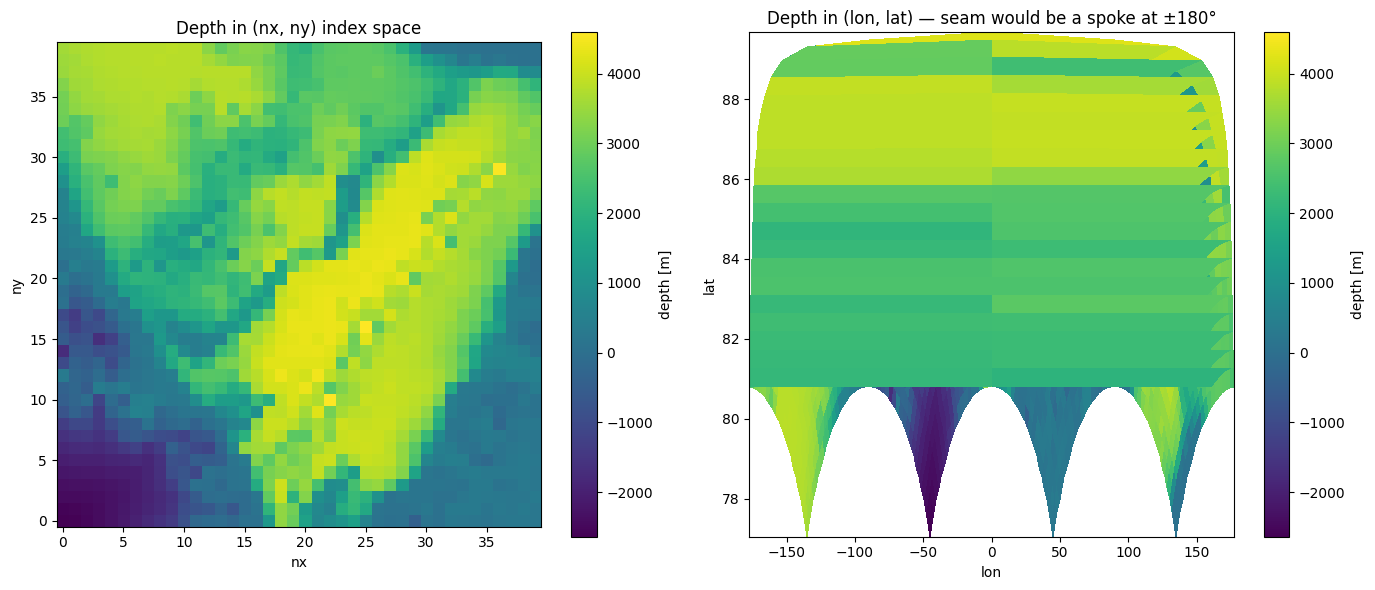

In [11]:
depth = topo.depth.values
tlon = arctic_grid.tlon.values
tlat = arctic_grid.tlat.values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im0 = axes[0].imshow(depth, origin="lower", cmap="viridis")
axes[0].set_title("Depth in (nx, ny) index space")
axes[0].set_xlabel("nx"); axes[0].set_ylabel("ny")
plt.colorbar(im0, ax=axes[0], label="depth [m]")

im1 = axes[1].pcolormesh(tlon, tlat, depth, cmap="viridis", shading="auto")
axes[1].set_title("Depth in (lon, lat) — seam would be a spoke at ±180°")
axes[1].set_xlabel("lon"); axes[1].set_ylabel("lat")
plt.colorbar(im1, ax=axes[1], label="depth [m]")

plt.tight_layout()
plt.show()

## 5. Numerical seam check

For every ocean cell within one grid spacing of the antimeridian, compare its depth to
the depth of its nearest neighbour on the *opposite* side of ±180°. Under the fix these
should agree to within normal bilinear interpolation error (a few metres to tens of
metres depending on local relief). Under the bug they diverge dramatically — cells inside
the source gap end up at `0` or `NaN`, or hold onto the initial `zeros_like(tarea)`
template value.

In [ ]:
# Find cells within ~1 grid spacing of the antimeridian by lon.
seam_band_deg = 5.0  # 50 km at ~70°N is ~1.5° lon; give it a comfortable band
near_seam = np.abs(np.abs(tlon) - 180.0) < seam_band_deg

n_seam = int(near_seam.sum())
print(f"{n_seam} cells within {seam_band_deg}° of the antimeridian")

seam_depths = depth[near_seam]
non_seam_depths = depth[~near_seam]

print(f"Seam-band depth stats:    mean={np.nanmean(seam_depths):>8.1f}  std={np.nanstd(seam_depths):>8.1f}  "
      f"nan_frac={np.isnan(seam_depths).mean():.3f}  zero_frac={(seam_depths == 0).mean():.3f}")
print(f"Rest-of-domain depth stats: mean={np.nanmean(non_seam_depths):>8.1f}  std={np.nanstd(non_seam_depths):>8.1f}  "
      f"nan_frac={np.isnan(non_seam_depths).mean():.3f}  zero_frac={(non_seam_depths == 0).mean():.3f}")

# The seam band should NOT be predominantly zero/nan when the fix is in place.
# (This is a soft check — real land in the Arctic sits at high lat too — but a huge
# zero-fraction spike relative to the rest of the domain is the diagnostic signature.)
seam_zero_frac = float((seam_depths == 0).mean())
rest_zero_frac = float((non_seam_depths == 0).mean())
print(f"\nseam_zero_frac / rest_zero_frac = {seam_zero_frac / max(rest_zero_frac, 1e-9):.2f}x")
print("(Under the bug this ratio blows up. Under the fix it stays ~1.)")